In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

df = pd.read_csv('/content/winequality-red.csv')
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides        

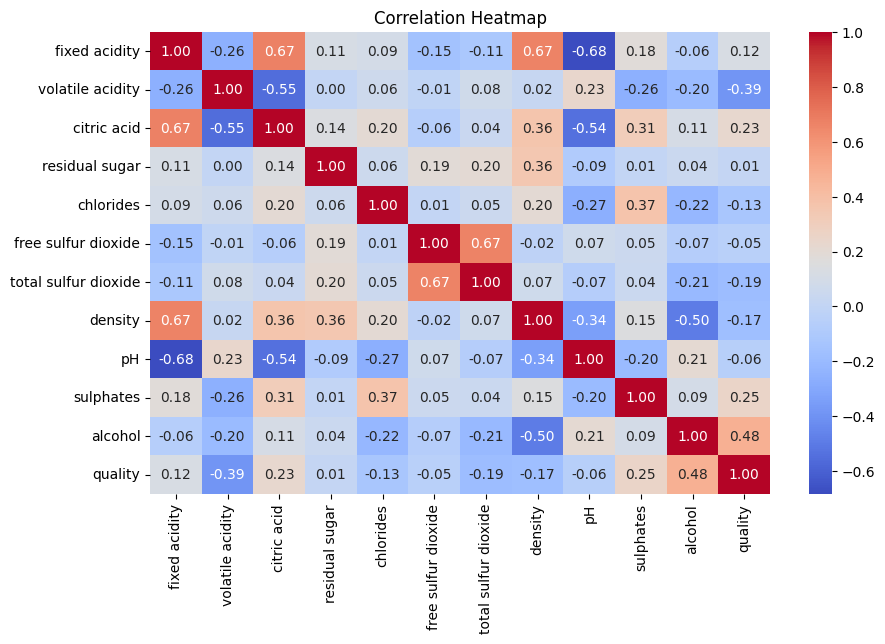

alcohol                 0.476166
volatile acidity        0.390558
sulphates               0.251397
citric acid             0.226373
total sulfur dioxide    0.185100
density                 0.174919
chlorides               0.128907
fixed acidity           0.124052
pH                      0.057731
free sulfur dioxide     0.050656
residual sugar          0.013732
Name: quality, dtype: float64


In [2]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

print(df.corr()['quality'].drop('quality').abs().sort_values(ascending=False))

In [3]:
df['quality'] = df['quality'].apply(lambda x: 1 if x >= 7 else 0)
print(df['quality'].value_counts())

X = df.drop('quality', axis=1)
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

quality
0    1382
1     217
Name: count, dtype: int64


In [4]:
def evaluate(name, model, features):
    pipe = Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('scale', StandardScaler()),
        ('model', model)
    ])
    pipe.fit(X_train[features], y_train)
    pred = pipe.predict(X_test[features])
    return {'Model': name,
            'Accuracy': round(accuracy_score(y_test, pred), 3),
            'F1 (good wine)': round(f1_score(y_test, pred), 3)}

In [5]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(criterion='entropy', random_state=42),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

all_features = list(X.columns)
results = [evaluate(n, m, all_features) for n, m in models.items()]
pd.DataFrame(results).sort_values('F1 (good wine)', ascending=False)

,Model,Accuracy,F1 (good wine)
4,Random Forest,0.916,0.697
5,Gradient Boosting,0.878,0.606
3,SVM,0.866,0.598
1,Decision Tree,0.850,0.556
0,Logistic Regression,0.825,0.548
2,KNN,0.816,0.543


In [6]:
top6 = df.corr()['quality'].drop('quality').abs().sort_values(ascending=False).index[:6].tolist()

reduced = [c for c in all_features if c not in ['density', 'fixed acidity', 'free sulfur dioxide']]

feature_sets = {'All 11': all_features, 'Top 6': top6, 'Reduced': reduced}

rows = []
for fs_name, feats in feature_sets.items():
    for n, m in models.items():
        r = evaluate(n, m, feats)
        r['Feature set'] = fs_name
        rows.append(r)

comp = pd.DataFrame(rows)
comp.pivot(index='Model', columns='Feature set', values='F1 (good wine)')

Feature set,All 11,Reduced,Top 6
Model,,,
Decision Tree,0.556,0.581,0.592
Gradient Boosting,0.606,0.619,0.594
KNN,0.543,0.571,0.564
Logistic Regression,0.548,0.553,0.550
Random Forest,0.697,0.674,0.667
SVM,0.598,0.556,0.542


In [7]:
pipe = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

params = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_leaf': [1, 3]
}

grid = GridSearchCV(pipe, params, scoring='f1', cv=5, n_jobs=-1)
grid.fit(X_train, y_train)
print('Best params:', grid.best_params_)

Best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}


In [8]:
pred = grid.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

Accuracy: 0.915625
[[262  15]
 [ 12  31]]
              precision    recall  f1-score   support

           0       0.96      0.95      0.95       277
           1       0.67      0.72      0.70        43

    accuracy                           0.92       320
   macro avg       0.82      0.83      0.82       320
weighted avg       0.92      0.92      0.92       320



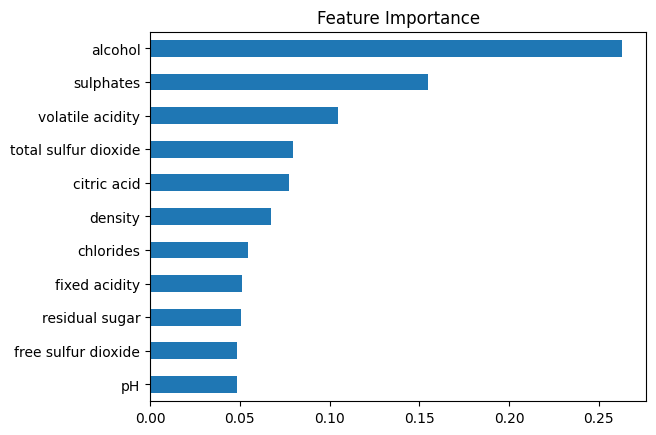

In [9]:
rf = grid.best_estimator_.named_steps['model']
pd.Series(rf.feature_importances_, index=all_features).sort_values().plot.barh(
    title='Feature Importance')
plt.show()

## Conclusion

- **Best model: Random Forest** – test accuracy 0.916 and F1 (good wine) 0.70. Gradient Boosting, SVM, Decision Tree, Logistic Regression and KNN ellaam athai vida kammi.
- Tree-based ensemble models nalla work aaguthu, yenna wine chemistry-la features-ku idaiyila non-linear relationships irukku.
- **Feature sets:** Random Forest-ku all 11 features use pannathu best. Top 6 and reduced feature sets Decision Tree and KNN-ku konjam help pannuchu, aana Random Forest-a beat pannala.
- **Feature importance:** alcohol, sulphates, volatile acidity ithu moonum quality-a athigama affect pannum features. Ithu EDA correlation results-oda match aaguthu.
- **Hyperparameter tuning:** GridSearchCV-la best params: n_estimators=400, max_depth=None, min_samples_leaf=1.
- **Accuracy mattum nambakoodathu:** Ella wine-um "bad"-nu predict pannaalum accuracy ~87% varum (class imbalance). Athunaala good-wine class-oda F1-score-um paarthen.
- **Data leakage thavirka:** Train-test split-ku appuram dhaan SMOTE and scaling apply pannen, so test results nijamaana performance-a kaattum.